# CA 1 Programming for AI - Postgraduate Diploma in AI

### Student Name: Sonia Ndonga
### Student Number: 26137216
### Date: 08/11/2026

# Introduction

The following project is to explore, research and evaluate the role of the artifical intelligence based on the online education as a Junior Programmer. For one reasearcher had to create a dataset that contains 500 rows by each student wihtin the online education programme and examine what are the relationships between each of the columns that are presented within the brief. The following techniques that were applied throughout the course of the project was data generation, data wrangling, data analysis and data visualisation based on the findings of the dataset that was created using fake data.

# Data Generation

### Importing the Libaries

In [7]:
# Importing the important libaries as follows below:

%matplotlib inline
import pandas as pd
import seaborn as sns
import numpy as np
import sklearn.preprocessing as preproc
import matplotlib.pyplot as plt
sns.set()

### Generating the student dataset for the online education

In [9]:
# Showing the reproduciblity of the random numbers as shown below:

random_number_generator = np.random.default_rng(42)

number_of_students = 500

study_hours = np.round(random_number_generator.uniform(0, 35, number_of_students), 2)

quiz_participations = random_number_generator.integers(0, 101, number_of_students)

past_performances = random_number_generator.integers(0, 101, number_of_students)

- `np.random.default_rng(42)` this makes the random number of the generator to be more consistent. By applying this it will create a program that can be able to have the same patterns based on the randomness of the values when rerunning the code. The `number 42` is just a chosen default number based on the value within the dataset. This will help to the consistency to more accessible when testing the code and confirming the outcome of the results [1].

- `np.round(random_number_generator.uniform(0, 35, number_of_students), 2)` creates the 500 random float values between 0 to 35 study hours.

- `random_number_generator.integers(0, 101, number_of_students)` creates the 500 random integer percentages between 0 and 100.

- `random_number_generator.integers(0, 101, number_of_students)` The same method structure applies and used towards the past performances.

### Creating the probable completion outcomes

In [12]:
# Creating the following probable completions for the outcomes with the randomness 

scores = (-3.0 + 0.09 * study_hours + 0.025 * quiz_participations
         + 0.025 * past_performances)

probability = 1 / (1 + np.exp( - scores))

course_completion = random_number_generator.random(number_of_students) < probability

### Creating the student dataframe for the dataset

In [14]:
# Creating the following student dataframe for the dataset

student_df = pd.DataFrame({
    'Student ID' : [f'S{i:03d}' for i in range (1, number_of_students + 1)],
    'Study hours': study_hours,
    'Quiz participation': quiz_participations,
    'Past performance': past_performances,
    'Course completion': course_completion,
})

- `range (1, number_of_students + 1)]` it creates the number of students that are from 1 to 501
- `f'S{i:03d}'` arranges the numbers that contain the letter S and the three digitals for example `S023`
- The following list of understanding generatea a unqiue ID's for each of the students

### Inputting the missing data on the rows in the following of the columns 

In [17]:
# Inputting the missing data as follows within the following rows within the student dataset

for column in ['Study hours', 'Quiz participation', 'Past performance']:
    indicies = random_number_generator.choice(number_of_students, size=12, replace=False)
    student_df.loc[indicies, column] = np.nan

### Inputting the void data towards the missing sections of the data

In [19]:
# Inputting the invalid data towards the missing sections of the data

for column, values in {
    'Study hours': [-5.0, -2.5, 168.0, 999.0] , 
    'Quiz participation': [-10, 110, 125, 150],
    'Past performance': [-15, 105, 120, 200],
}.items():
    accurate_indicies = student_df.index[student_df[column].notna()].to_numpy()
    indicies = random_number_generator.choice(accurate_indicies, size=len(values), replace=False)
    student_df.loc[indicies, column] = values

### Getting the null integer data types within the dataset

In [21]:
# Applying the null integer based on the data types within the dataset that retains the percentage columns within 
# the integral regarding on the missing values 

for column in ['Quiz participation', 'Past performance']:
    student_df[column] = student_df[column].astype('Int64')

### Outputting the following data generation as dataset csv file

In [23]:
# Outputting the following data as a csv file for the student dataset

student_df.to_csv('students_raw_data.csv', index=False)

print("The following files of students_raw_data.csv has been successfully saved.")

The following files of students_raw_data.csv has been successfully saved.


# 3. Data Wrangling

### Viewing the dataset

In [26]:
# Viewing the first five rows of the dataset using the head()

student_df.head(5)

,Student ID,Study hours,Quiz participation,Past performance,Course completion
0,S001,27.09,81,53,True
1,S002,15.36,74,26,True
2,S003,30.05,56,23,True
3,S004,24.41,89,32,True
4,S005,3.30,12,60,False


In [27]:
# Viewing the last five rows of the dataset using the tail()

student_df.tail(5)

,Student ID,Study hours,Quiz participation,Past performance,Course completion
495,S496,19.22,43,0,False
496,S497,15.10,55,55,False
497,S498,21.91,78,100,True
498,S499,12.62,<NA>,28,True
499,S500,17.95,84,28,True


### Checking the information about the student dataset

In [29]:
# Printing the information about the student dataset as shows:
# Displaying the number of rows, columns, datatypes following by others as shown below:

student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student ID          500 non-null    object 
 1   Study hours         488 non-null    float64
 2   Quiz participation  488 non-null    Int64  
 3   Past performance    488 non-null    Int64  
 4   Course completion   500 non-null    bool   
dtypes: Int64(2), bool(1), float64(1), object(1)
memory usage: 17.2+ KB


The following information of the student dataset indicates the following:

- Displays the dtype, column names and non-null values
- Demonstrates whether if it is a numerical or categorical data
- Show the number of rows as shown and gives an indication whether is there is missing values within the data.

### Checking the shape and data types within the student dataset

In [32]:
# Printing the shape of the student dataset

print("The shape of the student dataset is:", student_df.shape)


# The data dtypes based on each of the columns within the student dataset

print("\n The following Data Types based on the Student Dataset: \n", "\n", student_df.dtypes)

The shape of the student dataset is: (500, 5)

 The following Data Types based on the Student Dataset: 
 
 Student ID             object
Study hours           float64
Quiz participation      Int64
Past performance        Int64
Course completion        bool
dtype: object


- The following student dataset displays that there is **5 columns** and **500 rows**.
- Rows explains the number of observations within the dataset.
- Columns explains the number of attributes.

### Finding the following student dataset based on summary statistics

The following student dataset as follows will display the following main descrpitive of the statistics for each of the columns as shown.

In [36]:
# Summary statistics based on the following numeric columns as shown 

student_df.describe()

,Study hours,Quiz participation,Past performance
count,488.000000,488.0,488.0
mean,19.492357,51.112705,48.954918
std,46.068845,29.848653,30.689376
min,-5.000000,-10.0,-15.0
25%,8.055000,27.75,23.0
50%,17.410000,50.5,48.0
75%,26.155000,77.0,75.0
max,999.000000,150.0,200.0


### Checking for missing values within the dataset

Reviewing the student dataset to indicate whether if it has missing values before investigating the dataset further.

In [39]:
# Checking the dataset for an indication of null or missing values

student_df.isnull().sum()

Student ID             0
Study hours           12
Quiz participation    12
Past performance      12
Course completion      0
dtype: int64

- The `isnull()` methods checks for missing values within the dataset
- The `sum()` method counts how many missing values in each of the columns within the dataset

### Getting the total missing values

In [42]:
# Getting the missing values for the student dataset

total_missing_values = student_df.isnull().sum().sum()

print(f"The total missing values within the student dataset: {total_missing_values}")

The total missing values within the student dataset: 36


The results of the database displays the following:

- Study hours is missing `12 values`.
- Quiz participation is missing `12 values`.
- Past performance is missing `12 values`.

A total of `36 missing values` within the student dataset

### Changing the numerical columns and dropping the rows that contain missing values

In [45]:
# Removing the missing values that are within the dataset within the numerical columns

numerical_columns = ["Study hours", "Quiz participation", "Past performance"]

for columns in numerical_columns:
    student_df[columns] = pd.to_numeric(student_df[columns], errors="coerce")

original_data_rows = len(student_df)

student_df_cleaned = student_df.dropna(subset=numerical_columns, thresh=2).copy()

print("The following rows have been removed:", original_data_rows - len(student_df_cleaned))

The following rows have been removed: 1


Based on the `numerical columns` it contains three of the numerical columns, the `subset=numerical` restricts the missing values in order to check of the following columns as shown. The `thresh=2` maintains the rows that are within the two na/not a number missing values. So the following rows that contained two to three missing numerical values were removed within the dataset. This method helps to prevent retained records that contain lot of missing information within the dataset.

### Adding the missing values with the median towards the dataset

In [48]:
# Replacing the missing values within the median based on the numerical columns of the dataset

for columns in numerical_columns:
    getting_median_value = student_df_cleaned[columns].median()

    if pd.notna(getting_median_value):
        if student_df_cleaned[columns].dtype == "Int64" and getting_median_value % 1 != 0:
            student_df_cleaned[columns] = student_df_cleaned[columns].astype("Float64")

    student_df_cleaned[columns] = student_df_cleaned[columns].fillna(getting_median_value)

# Printing the missing values within the dataset

print(student_df_cleaned.isna().sum())

Student ID            0
Study hours           0
Quiz participation    0
Past performance      0
Course completion     0
dtype: int64


- The `for loop` handles each of the numerical column within the dataset.
- The `median value` estimates the middle value of the dataset.
- The `fillna()` method replaces the missing values that are within the median within the dataset.
- The `median` is helpful as this is not effected towards the peak values compared to the mean.

### Checking the uneven values within the student dataset

In [51]:
# Checking to see if there is uneven values indicated within the student dataset

print("The null study hours are:", (student_df_cleaned["Study hours"].between(0, 35)).sum())

print("The null quiz participation are:", (student_df_cleaned["Quiz participation"].between(0, 100)).sum())

print("The null past peformance are:", (student_df_cleaned["Past performance"].between(0, 100)).sum())

The null study hours are: 495
The null quiz participation are: 495
The null past peformance are: 495


Checking for any null mismatched values before applying data wrangling by applying `sum()` method and getting the columns for `Study Hours, Quiz Participation and Past Performance` within the dataset.

### Correcting the uneven values within the student dataset

In [54]:
# Correcting the uneven values within the dataset

student_df_cleaned["Study hours"] = student_df_cleaned["Study hours"].clip(0, 35)

student_df_cleaned["Quiz participation"] = student_df_cleaned["Quiz participation"].clip(0, 100).round().astype(int)

student_df_cleaned["Past performance"] = student_df_cleaned["Past performance"].clip(0, 100).round().astype(int)

- The `clip()` method prevents the numerical values based on a defined range. For instance based on the study hours if the value is displayed as -4  it will develop into 0 in the other hand the quiz participation value of 120 will develop into 100. This will verfiy based on the numerical values will keep its their reasonable threshold within the dataset.

### Normalising the study hours for the student dataset

In [57]:
# Normalising the study hours wihtin the student dataset

minimum_hours = student_df_cleaned["Study hours"].min()

maximum_hours = student_df_cleaned["Study hours"].max()


if maximum_hours > minimum_hours:
    student_df_cleaned["Normalised Study Hours"] = (student_df_cleaned ["Study hours"] - minimum_hours) / (maximum_hours - minimum_hours)

else:
    student_df_cleaned["Normalised Study Hours"] = 0.0

- `min()` method finds the minimum study hours value
- `max()` method finds the maximum
- Based on the min-max normalisation it converts the study hours based on the ranges between 0 and 1

In a scenario where the minimum of the hour is 0 and the maximum is 35 whereas the student has studied the total hours of 17.5 would end of getting a normalised score of 0.5. The if and else condition includes the following where to prevent the divison of zero based on the minimum and maximum were in equal terms.

### Calculating the engagment scores of the student dataset

In [60]:
# Calculating the following engagement scores based on the dataset 

student_df_cleaned["Engagement Scores"] = (
    0.6 * student_df_cleaned["Normalised Study Hours"] +
    0.4 * student_df_cleaned["Quiz participation"] / 100
)

- `Normalised Study Hours` presents the **60%**
- `Quiz participation` presents the **40%**
- Dividing the `quiz participation` by **100** it will change the percentage towards a values halfway between **0 and 1**.

Based on the results of the engagements scores it will display between 0 and 1. The highest score will display on whether the greater engagement towards the following given formula. 

### Rounding the values of the student dataset

In [63]:
# Rounding the values of the student dataset 

student_df_cleaned["Study hours"] = student_df_cleaned["Study hours"].round(2)

student_df_cleaned["Quiz participation"] = student_df_cleaned["Quiz participation"].round(4)

student_df_cleaned["Engagement Scores"] = student_df_cleaned["Engagement Scores"].round(4)

### Validating the cleaned student dataset

In [65]:
# Validating the cleaned student dataset as follows:

print("The number of rows within the student dataset:", len(student_df_cleaned))

print("The following missing values within the student dataset are:", student_df_cleaned.isna().sum().sum(), "\n")

for columns, low, high in [("Study hours", 0, 35), ("Quiz participation", 0, 100), ("Past performance", 0, 100),
                          ("Normalised Study Hours", 0, 1), ("Engagement Scores", 0, 1)]:
    print(columns, ":", student_df_cleaned[columns].between(low, high).all())

The number of rows within the student dataset: 499
The following missing values within the student dataset are: 0 

Study hours : True
Quiz participation : True
Past performance : True
Normalised Study Hours : True
Engagement Scores : True


### Outputting the following data generation as a cleaned student dataset csv file

In [67]:
# Outputing the following cleaned data as a csv file as a cleaned student dataset

student_df_cleaned.to_csv('students_cleaned_data.csv', index=False)

print("The following files of students_cleaned_data.csv has been successfully saved.")

The following files of students_cleaned_data.csv has been successfully saved.


# 4. Data Analysis 

### Viewing the cleaned student dataset

In [70]:
# Viewing the first five rows of the cleaned dataset using the head()

student_df_cleaned.head(5)

,Student ID,Study hours,Quiz participation,Past performance,Course completion,Normalised Study Hours,Engagement Scores
0,S001,27.09,81,53,True,0.774000,0.7884
1,S002,15.36,74,26,True,0.438857,0.5593
2,S003,30.05,56,23,True,0.858571,0.7391
3,S004,24.41,89,32,True,0.697429,0.7745
4,S005,3.30,12,60,False,0.094286,0.1046


In [71]:
# Viewing the last five rows of the cleaned dataset using the tail()

student_df_cleaned.tail(5)

,Student ID,Study hours,Quiz participation,Past performance,Course completion,Normalised Study Hours,Engagement Scores
495,S496,19.22,43,0,False,0.549143,0.5015
496,S497,15.10,55,55,False,0.431429,0.4789
497,S498,21.91,78,100,True,0.626000,0.6876
498,S499,12.62,50,28,True,0.360571,0.4163
499,S500,17.95,84,28,True,0.512857,0.6437


### Checking the information of the cleaned student dataset

In [73]:
# Printing the information about the cleaned student dataset as shows:

student_df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 499 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Student ID              499 non-null    object 
 1   Study hours             499 non-null    float64
 2   Quiz participation      499 non-null    int32  
 3   Past performance        499 non-null    int32  
 4   Course completion       499 non-null    bool   
 5   Normalised Study Hours  499 non-null    float64
 6   Engagement Scores       499 non-null    float64
dtypes: bool(1), float64(3), int32(2), object(1)
memory usage: 23.9+ KB


### Checking the shape of the cleaned student dataset

In [75]:
# Observing the shape of the cleaned student dataset

print("The shape of the cleaned student dataset is:", student_df_cleaned.shape)

The shape of the cleaned student dataset is: (499, 7)


### Finding the following cleaned student dataset based on summary statistics

In [77]:
# Looking at the cleaned student dataset using the summary statistics and rounding the numeric values within 2 decimal places
# Applied the transpose method to get a better overview of the dataset

student_df_cleaned.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Study hours,499.0,17.26,10.00,0.00,8.24,17.41,26.08,35.00
Quiz participation,499.0,50.94,29.08,0.00,28.00,50.00,76.50,100.00
Past performance,499.0,48.65,29.48,0.00,23.00,48.00,74.00,100.00
Normalised Study Hours,499.0,0.49,0.29,0.00,0.24,0.50,0.74,1.00
Engagement Scores,499.0,0.50,0.21,0.03,0.33,0.49,0.65,0.98


### Looking at the summary statistics for mean, median and standard deviation for the cleaned dataset

In [79]:
# Observing the overview for the summary statistics for the mean, median and standard deviation for the student dataset

summary_statistics = student_df_cleaned[["Study hours", "Quiz participation"]].agg(["mean", "median", "std"])
summary_statistics.round(2)

,Study hours,Quiz participation
mean,17.26,50.94
median,17.41,50.00
std,10.00,29.08


Based on the summary statistics the following cleaned dataset indicate the following:

- The average study hours as shown indicates about `17.26 for mean`,  `17.41 for median` and `10.00 for standard deviation`
- For the quiz participation it displayed as shown `50.94 for mean`,  `50.00 for median` and `29.08 for standard deviation`

The following data from the student dataset displays a reasonable variation.

The columns for `Study Hours` and `Quiz Participation` gets the two numerical variable for the analysis from the dataset.

- `agg()` method outputs the multiple statistical estimations
- `mean` method gets the average
- `median` method estimates the middle value
- `std` method is estimating the data standard deviation
- `round(2)` shows the print outputs for two decimal values

### Comparing the summary statistics for the engagement comparision from the completion status from the dataset

In [83]:
# Comparing the summary statistics for the engagement comparision based on the completion status

display_engagement_comparison = student_df_cleaned.groupby("Course completion")["Engagement Scores"].agg(["count", "mean"])

display_engagement_comparison.round(4)

,count,mean
Course completion,,
False,170,0.3745
True,329,0.5644


Regarding on the course completion, the overall average displays as `0.56 as students have completed` and  `0.37 as students have not completed`.
Based on the organisation the following data indicates that the following data is dummy data as there is not enough observational evidence. Students who have completed the course have a higher engagement scores compared to the ones that have not completed. This presents there is a positive relationship betwween the engagment and compeletion within the dummy data from the dataset.

The column for `Course completion` gathers the count and mean for the analysis from the dataset

- `groupby()` it divides the students based on whether they have completed the courses.
- `Engagement Score` it gathers the variable that has been examined
- `count` method it estimates the number of students that are within the group
- `mean` method estimates the average engagement from the students
- `round(2)` shows the print outputs for two decimal values

### Getting the filter engagement with the following scores above 0.70

In [87]:
# Applying the filter engagement for the scores that are above 0.70

display_high_engagement = student_df_cleaned[student_df_cleaned["Engagement Scores"] > 0.70]
print("The following students that have above 0.70 are:", len(display_high_engagement))

print("The percentage of the scores are:", round(len(display_high_engagement) / len(student_df_cleaned) * 100, 1), "%")

# Showing the high engagement table

display_high_engagement.head()

The following students that have above 0.70 are: 96
The percentage of the scores are: 19.2 %


,Student ID,Study hours,Quiz participation,Past performance,Course completion,Normalised Study Hours,Engagement Scores
0,S001,27.09,81,53,True,0.774000,0.7884
2,S003,30.05,56,23,True,0.858571,0.7391
3,S004,24.41,89,32,True,0.697429,0.7745
5,S006,34.15,93,24,True,0.975714,0.9574
6,S007,26.64,85,92,True,0.761143,0.7967


In [88]:
# Showing the high engagment table for the tail()

display_high_engagement.tail()

,Student ID,Study hours,Quiz participation,Past performance,Course completion,Normalised Study Hours,Engagement Scores
439,S440,22.05,96,20,False,0.630000,0.7620
440,S441,29.79,78,16,True,0.851143,0.8227
446,S447,34.31,94,15,True,0.980286,0.9642
447,S448,21.40,96,92,True,0.611429,0.7509
467,S468,32.92,38,47,True,0.940571,0.7163


Based on the results 96 students that have delivered the engagement score of 70 and above. The estimation of the percentage scores are `19.2%` based on the students that have shown based on the high engagement based on the chosen threshold.


- `student_df_cleaned["Engagement Scores"] > 0.70]` verfies the which of the students have scored above `70%` or `0.70`
- `Engagement Scores` was selected based on the condition of the data
- `display_high_engagement` retains the following fitered dataset
- The `head()` method print the output based on the first five rows of the dataset
- The `tail()` method print the output based on the last five rows of the dataset

### Applying the classifying performance with the apply and lambda for the dataset

In [92]:
# Applying the classifying perfomance with apply and lambda using "Low", "Medium" and "High"

student_df_cleaned["Performance categories"] = student_df_cleaned["Past performance"].apply(
    lambda get_x: "High" if get_x >= 70 else "Medium" if get_x >=40 else "Low"
)

# Showing the classifying performance using head
student_df_cleaned[["Student ID", "Past performance", "Performance categories"]].head()

,Student ID,Past performance,Performance categories
0,S001,53,Medium
1,S002,26,Low
2,S003,23,Low
3,S004,32,Low
4,S005,60,Medium


In [93]:
# Showing the classifying performance using tail
student_df_cleaned[["Student ID", "Past performance", "Performance categories"]].tail()

,Student ID,Past performance,Performance categories
495,S496,0,Low
496,S497,55,Medium
497,S498,100,High
498,S499,28,Low
499,S500,28,Low


- The `apply` method handles all of the values that are within the `Past Performance` column
- `lambda` and `get_x` method explains the short unnamed function
-  `if get_x >= 70` highlights the classifed students that are selected as `High`
-  `else "Medium" if get_x >=40` are grouped based on the students that have scores between 40 and 69 as `Medium`
-  `else "Low"` is grouped by the students that have scored below 40 that categorised as `Low`

### Showing the count performance display categories for the student database

In [133]:
# Displaying the count performance for the student dataset

display_count_performance = student_df_cleaned["Performance categories"].value_counts()

display_count_performance

Performance categories
Low       210
High      147
Medium    142
Name: count, dtype: int64

The following data shows the following:

- `210 students` categorise in the **Low** Section performances.
- `147 students` categorise in the **High** Section performances.
- `142 students` categorise in the **Medium** Section performances.

### Applying the performance display categories plot graph to get a better overview of the data 

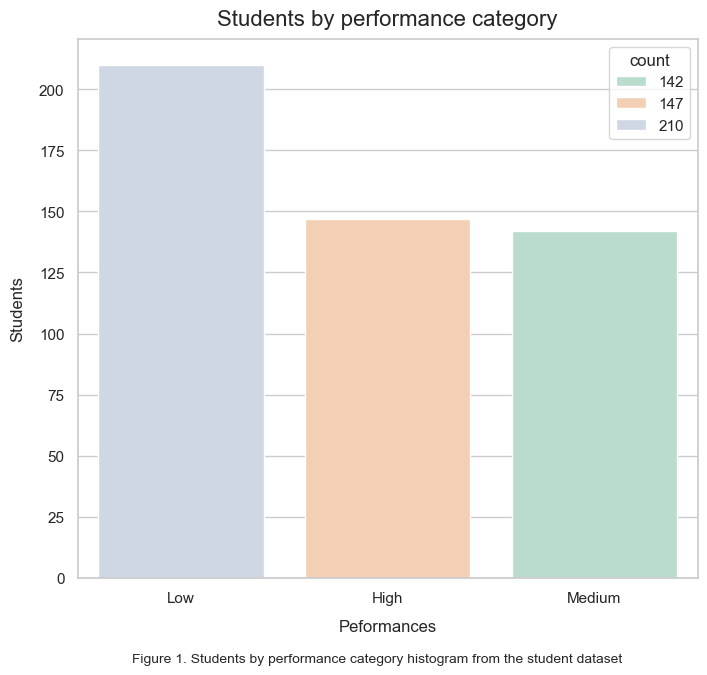

In [137]:
# Setting the visual background style for the histogram
sns.set(style="whitegrid")

# Plotting the class distribution for the performance category
plt.figure(figsize=(8, 7))
sns.barplot(x=display_count_performance.index, y=display_count_performance.values, hue=display_count_performance, palette="Pastel2")
plt.title("Students by performance category", pad=10, fontsize=16)
plt.xlabel("Peformances", labelpad=10)
plt.ylabel("Students", labelpad=10)
plt.xticks(rotation=0)
plt.figtext(0.5, -0.01, "Figure 1. Students by performance category histogram from the student dataset", ha="center", fontsize=10)
plt.savefig("Students_By_Performance_Plot_Graph.png", dpi=300, bbox_inches="tight")
plt.show()

Based on the visualisation the `Low Performance` section has collected the largest number of students in which demonstrates the following higher proportion scored below 40% that was chosen by the grading system within the dataset.

The largest group of the `Low Performance` section has `210 students` followed by the `Medium Performance` section has `142 students` and the `High Performance` section has `147 students` as displayed.